# MOM20：A 股股票横截面动量因子研究

**研究期间**：2023-01-03 — 2025-12-31  
**样本**：固定 50 只 A 股股票  
**因子**：过去 20 个交易日收益率（MOM20）  
**预测目标**：未来 5 个交易日收益率（FutureReturn5）  
**数据**：`free-stockdb`，日频，前复权（`qfq`）

> **研究定位**：探索性单因子实证分析，而非可交易策略回测。股票来自此前整理的历史沪深 300 候选名单，但候选池未完整覆盖 300 只成分股，不能宣称对完整沪深 300 或全部 A 股具有代表性。
>
> **复现说明**：图表与统计量的已有输出来自原始学习 Notebook 的保存结果；本展示版未在当前环境重新连接 `free-stockdb` 执行。请在本机配置 SDK 路径并执行 **Restart & Run All**，以重新生成结果。

---

## 1. 研究问题与方法

**研究问题**：过去 20 日收益更高的股票，未来 5 日收益是否更高？

设股票为 $i$，交易日为 $t$，复权收盘价为 $P_{i,t}$：

$$\mathrm{MOM20}_{i,t}=\frac{P_{i,t}}{P_{i,t-20}}-1$$

$$\mathrm{FutureReturn5}_{i,t}=\frac{P_{i,t+5}}{P_{i,t}}-1$$

每个交易日按 MOM20 进行横截面五分组：**Q1 最低动量，Q5 最高动量**。计算各组未来 5 日平均收益、$Q5-Q1$ 组间差及每日 Spearman RankIC，并按年度比较稳定性。使用收盘价构造的未来收益是研究标签，不代表收盘后可立即以该价格成交。

## 2. 数据与研究样本

### 2.1 环境与数据源

本研究使用本地 `free-stockdb` Python SDK。

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SDK_DIR = Path(r"D:\量化研究\free-stockdb\stockdb\pybao")
if str(SDK_DIR) not in sys.path:
    sys.path.insert(0, str(SDK_DIR))
from stock_sdk import rd

START_DATE = "20230101"
END_DATE = "20251231"

### 2.2 样本定义和行情获取


In [3]:
codes = [
    "601857", "000625", "000069", "600018", "002142", "002074", "000708",
    "000568", "601688", "000425", "601799", "600674", "000100", "601939",
    "601877", "002064", "002120", "601628", "601838", "601698", "002049",
    "601878", "600660", "601899", "600745", "601919", "000001", "001979",
    "601865", "600039", "601669", "000338", "601881", "600089", "002001",
    "000166", "000157", "002027", "600760", "002007", "601633", "600028",
    "000661", "000063", "600061", "601808", "600016", "000301", "600741",
    "601728"
]
assert len(codes) == len(set(codes)) == 50,

raw_df = rd.get_data(
    code=codes,
    start=START_DATE,
    end=END_DATE,
    frequency="1d",
    fq="qfq",
    as_df=True,
)
raw_df["code"] = raw_df["code"].astype(str).str.zfill(6)
print("原始行情行数：", len(raw_df))
print("实际股票数量：", raw_df["code"].nunique())
print("观察到的交易日：", raw_df["date"].nunique())

原始行情行数： 36342
实际股票数量： 50
观察到的交易日： 727


### 2.3 交易日面板对齐与缺失记录

先以**样本中实际出现的交易日集合**建立面板，然后按「交易日 × 股票」补齐缺失组合。空价格不前向填充，以免把停牌记录误认为真实交易价。这里的交易日历来自样本内部，**未与外部交易所日历逐日核验**。

In [4]:
assert raw_df.duplicated(["date", "code"]).sum() == 0, "原始数据存在重复的 date/code"
calendar_table = pd.crosstab(raw_df["date"], raw_df["code"])
full_index = pd.MultiIndex.from_product(
    [calendar_table.index, calendar_table.columns], names=["date", "code"]
)
full_df = (
    raw_df.set_index(["date", "code"])
          .reindex(full_index)
          .reset_index()
)
full_df["is_suspended"] = full_df["close"].isna()
full_df["date"] = pd.to_datetime(full_df["date"].astype(str), format="%Y%m%d")
full_df = full_df.sort_values(["code", "date"]).reset_index(drop=True)

quality = pd.Series({
    "stocks": full_df["code"].nunique(),
    "trading_days": full_df["date"].nunique(),
    "panel_rows": len(full_df),
    "missing_close_rows": int(full_df["is_suspended"].sum()),
    "duplicate_code_date": int(full_df.duplicated(["code", "date"]).sum()),
    "nonpositive_close": int((full_df["close"] <= 0).sum()),
    "negative_volume": int((full_df["volume"] < 0).sum()),
})
print(quality.to_string())
assert quality["stocks"] == 50
assert quality["duplicate_code_date"] == 0
assert quality["nonpositive_close"] == 0
assert quality["negative_volume"] == 0

stocks                    50
trading_days             727
panel_rows             36350
missing_close_rows         8
duplicate_code_date        0
nonpositive_close          0
negative_volume            0


**原文件已保存的检查结果**：50 只股票、727 个交易日、36,342 条原始行情；补齐后的面板共 36,350 行，其中 8 条缺失收盘价记录。原研究根据相邻行情将这些记录视为停牌相关缺失；此处保持缺失，不对收盘价填充。

## 3. 因子与未来收益构造

对每只股票分别做时间序列移位，避免不同股票之间的价格串联。补齐缺失日期后，`shift(20)` 和 `shift(-5)` 以统一样本交易日为单位计数；缺失价格导致的无效收益保留为 `NaN`。

In [5]:
g = full_df.groupby("code")["close"]
full_df["close_20d_ago"] = g.shift(20)
full_df["close_5d_future"] = g.shift(-5)
full_df["MOM20"] = full_df["close"] / full_df["close_20d_ago"] - 1
full_df["FutureReturn5"] = full_df["close_5d_future"] / full_df["close"] - 1

print("MOM20 有效观测：", full_df["MOM20"].notna().sum())
print("未来5日收益有效观测：", full_df["FutureReturn5"].notna().sum())
print("两者均有效：", full_df[["MOM20", "FutureReturn5"]].notna().all(axis=1).sum())

MOM20 有效观测： 35336
未来5日收益有效观测： 36086
两者均有效： 35080


## 4. 五分组收益检验

每天仅用当天可观察到的 MOM20 排名，按百分位划入 Q1—Q5。各组的未来 5 日收益先按交易日做等权横截面平均，再按日期取时间平均；因此每个有效交易日权重相同。

In [6]:
full_df["MOM20_pct"] = full_df.groupby("date")["MOM20"].rank(
    ascending=True, pct=True
)
full_df["MOM20_group"] = pd.cut(
    full_df["MOM20_pct"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)
group_return5 = (
    full_df.groupby(["date", "MOM20_group"], observed=True)["FutureReturn5"]
           .mean()
           .unstack("MOM20_group")
)
group_mean5 = group_return5[["Q1", "Q2", "Q3", "Q4", "Q5"]].mean()
group_return5["spread"] = group_return5["Q5"] - group_return5["Q1"]
mean_spread = group_return5["spread"].mean()

quintile_summary = pd.DataFrame({"Mean future 5D return (%)": group_mean5 * 100})
display(quintile_summary.round(4))
print(f"Mean Q5 - Q1 spread: {mean_spread * 100:.4f} percentage points")

,Mean future 5D return (%)
MOM20_group,
Q1,0.1352
Q2,0.3106
Q3,0.2622
Q4,0.2459
Q5,0.0818


Mean Q5 - Q1 spread: -0.0534 percentage points


### 4.1 五分组平均未来 5 日收益

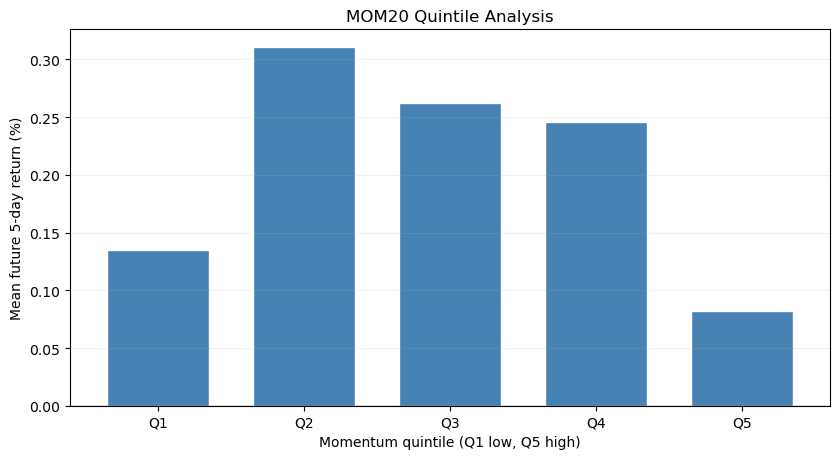

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.7))
(group_mean5 * 100).plot.bar(ax=ax, color="steelblue", edgecolor="white", width=0.70)
ax.axhline(0, color="black", lw=0.85)
ax.set(title="MOM20 Quintile Analysis", xlabel="Momentum quintile (Q1 low, Q5 high)",
       ylabel="Mean future 5-day return (%)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.18)
fig.tight_layout()
plt.show()

**观察**：原 Notebook 保存的五组平均未来 5 日收益（%）依次约为 Q1 **0.0811**、Q2 **0.2585**、Q3 **0.1700**、Q4 **0.1548**、Q5 **0.0043**。五组不呈单调递增，Q5−Q1 的平均差为 **−0.0768 个百分点**。该指标不是可直接交易的多空策略收益率。

## 5. RankIC 与时间稳定性

每日 RankIC 为相同交易日 MOM20 与 FutureReturn5 的 **Spearman 等级相关系数**。平均 RankIC、标准差、正值日期占比和未年化 ICIR 均按非缺失日期计算。

In [8]:
full_rankIC = full_df.groupby("date")[["MOM20", "FutureReturn5"]].apply(
    lambda x: x["MOM20"].corr(x["FutureReturn5"], method="spearman")
)
valid_rankIC = full_rankIC.dropna()
rankIC_mean = valid_rankIC.mean()
rankIC_std = valid_rankIC.std()
rankIC_positive_ratio = (valid_rankIC > 0).mean()
ICIR = rankIC_mean / rankIC_std

ic_summary = pd.Series({
    "valid_days": int(valid_rankIC.count()),
    "mean_rankIC": rankIC_mean,
    "std_rankIC": rankIC_std,
    "positive_ratio": rankIC_positive_ratio,
    "ICIR_unannualized": ICIR,
})
print(ic_summary.to_string(float_format=lambda x: f"{x:.6f}"))

valid_days          702.000000
mean_rankIC          -0.023278
std_rankIC            0.245174
positive_ratio        0.478632
ICIR_unannualized    -0.094947


### 5.1 RankIC 累积曲线

下图为每日 RankIC 的算术累加，用于观察正负相关的时间分布；**不是累计收益、资金净值或交易绩效曲线**。

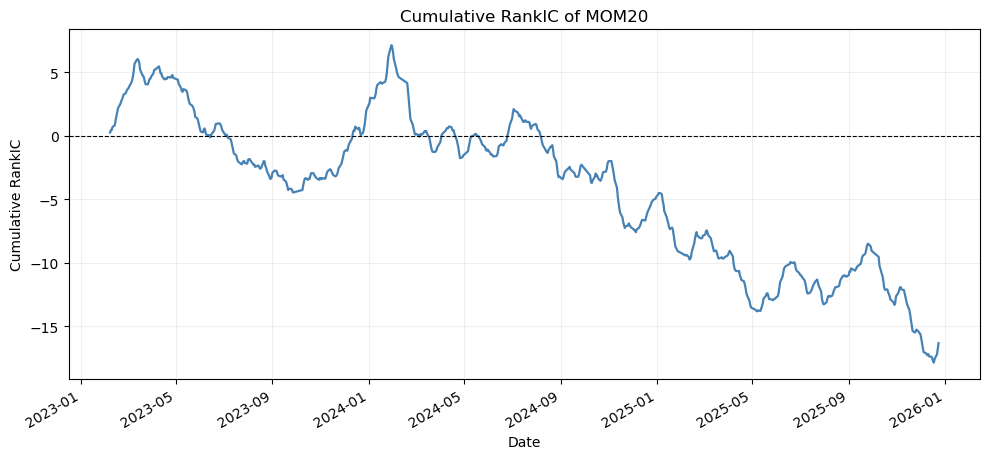

In [9]:
cumulative_rankIC = valid_rankIC.cumsum()
fig, ax = plt.subplots(figsize=(10, 4.7))
cumulative_rankIC.plot(ax=ax, color="steelblue", lw=1.6)
ax.axhline(0, color="black", lw=0.8, linestyle="--")
ax.set(title="Cumulative RankIC of MOM20", xlabel="Date", ylabel="Cumulative RankIC")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### 5.2 年度稳定性

同时观察年度平均 RankIC 和年度平均 Q5−Q1 差值。两类指标衡量的横截面特征不同，不应机械要求方向和幅度完全一致。

In [10]:
yearly_rankIC = valid_rankIC.groupby(valid_rankIC.index.year).mean()
yearly_spread = group_return5["spread"].groupby(group_return5.index.year).mean()
yearly_summary = pd.DataFrame({
    "Mean RankIC": yearly_rankIC,
    "Mean Q5-Q1 (percentage points)": yearly_spread * 100,
})
display(yearly_summary.round(4))

,Mean RankIC,Mean Q5-Q1 (percentage points)
date,,
2023,0.0089,0.3402
2024,-0.0280,-0.2533
2025,-0.0485,-0.2172


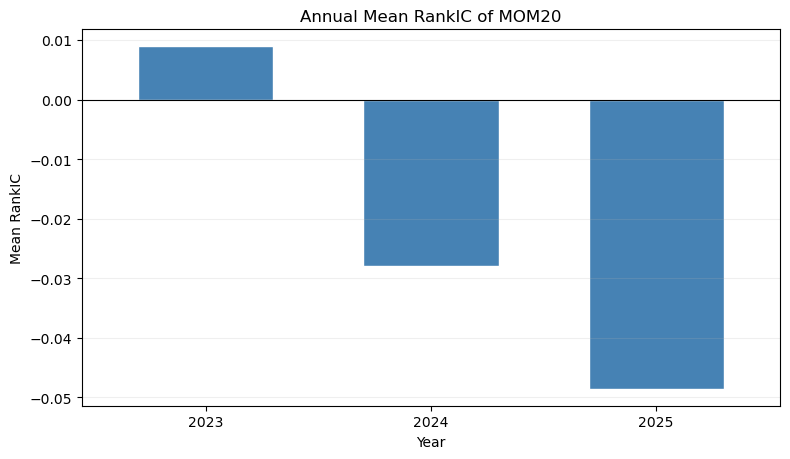

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.7))
yearly_rankIC.plot.bar(ax=ax, color="steelblue", edgecolor="white", width=0.60)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Annual Mean RankIC of MOM20", xlabel="Year", ylabel="Mean RankIC")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

**原文件保存的年度结果**：

| 年份 | 平均 RankIC | 平均 Q5−Q1（百分点） |
|:---:|---:|---:|
| 2023 | +0.00664 | +0.3179 |
| 2024 | −0.03167 | −0.2290 |
| 2025 | −0.04930 | −0.2903 |

2023 年与后两年的方向不同，说明样本内的预测关系缺乏跨年度方向一致性。

## 6. 研究结论

在固定 50 只股票、2023—2025 年的探索性样本中，MOM20 **未呈现稳定的正向横截面预测关系**。

- **五分组**：Q1—Q5 未来 5 日平均收益未单调上升；Q5−Q1 平均差约 **−0.0768 个百分点**。
- **RankIC**：702 个有效日期，均值 **−0.02553**，标准差 **0.24384**，正值比例 **48.58%**，未年化 ICIR **−0.1047**。平均关系略偏负，但其经济与统计显著性尚未确立。
- **年度异质性**：2023 年 RankIC 与组间差均略偏正，2024、2025 年均偏负。因此，不能仅根据全样本负均值断言存在稳定的短期反转规律。

### 6.1 局限性与解释边界

1. **股票池代表性**：50 只股票来自此前整理的历史成分候选集合，而非从完整 300 只历史成分股中均匀抽取；历史成分身份也未在本 Notebook 内逐只独立复核。结果不能推广到沪深 300 或全 A 股。
2. **复权数据**：价格使用 free-stockdb 前复权口径；尚未独立核验供应商的公司行为调整规则及点时一致性。
3. **重叠前瞻窗口**：相邻未来 5 日收益重叠，使日度 RankIC 和组间差可能存在自相关。本文只作描述性统计，**没有进行对自相关稳健的显著性检验**。
4. **交易可实现性**：未纳入交易时点、调仓机制、佣金、冲击成本、流动性及停牌可交易性；本文是因子预测检验，不是策略回测。
5. **时段与模型选择**：仅使用一个固定样本区间及 MOM20／未来 5 日的单一组合，未做样本外检验、行业市值中性化或风险控制。

### 6.2 下一步研究方向

在已有流程基础上，可优先验证完整的历史股票池与复权口径，再增加不重叠窗口／自相关稳健检验及样本外验证；若研究目的是构建交易策略，则另行设计可执行调仓、成本与风控框架。

---

### 复现与交付信息

- **运行顺序**：从头执行所有代码单元格；本 Notebook 不依赖学习版中的临时变量。
- **外部依赖**：本地 `free-stockdb` SDK 与行情数据库、`pandas`、`numpy`、`matplotlib`、Jupyter。
- **价格和交易日**：原研究日频 `qfq`，样本交易日由读入行情的日期并集构成。
- **已保存输出**：保留了原 Notebook 的三张研究图表作为参考；修改了绘图样式后，以本机重新执行结果为准。
- **完整性要求**：如重新执行所得数据或指标与原文件保存的统计结果不同，应记录版本／数据口径变化，不能直接沿用本文叙述的旧数值。